## Import packages

In [1]:
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
import os
import gc
import unicodedata
import html
import re
import json
import glob
import numpy as np
import pandas as pd
import pathlib
import torch
import torch.nn as nn
from datasets import Dataset, DatasetDict
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding, pipeline
from peft import LoraConfig, get_peft_model, PeftModel
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)
from collections import Counter
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt


import warnings
warnings.filterwarnings("ignore")

## Inputs

In [3]:
INPUT_DIR = pathlib.Path("/kaggle/input")

COMPETITIONS_DIR = sorted([
    p for p in (INPUT_DIR / "competitions").iterdir()
    if p.is_dir()
])

DATASET_DIR = sorted([
    p for p in (INPUT_DIR / "datasets").iterdir()
    if p.is_dir()
])

MODEL_DIR = sorted([
    p for p in (INPUT_DIR / "models").iterdir()
    if p.is_dir()
])


print("Competitions directories:", len(COMPETITIONS_DIR))
for path in COMPETITIONS_DIR:
    for file_path in path.rglob("*"):
        if file_path.is_file():
            path_str = str(file_path)
            print(path_str)
    
print("\nDataset directories:", len(DATASET_DIR))
for path in DATASET_DIR:
    print(path)

print("\nModel directories:", len(MODEL_DIR))
for path in MODEL_DIR:
    print(path)

Competitions directories: 1
/kaggle/input/competitions/name-that-llm/sample_submission.parquet
/kaggle/input/competitions/name-that-llm/train.csv
/kaggle/input/competitions/name-that-llm/test.csv

Dataset directories: 1
/kaggle/input/datasets/pawankumargunjan

Model directories: 1
/kaggle/input/models/answer-ai


## Read the datasets

In [4]:
# competitions training data
TRAIN_PATH = (
    INPUT_DIR / "competitions/name-that-llm/train.csv"
)

# Original competition dataset
train_df = pd.read_csv(TRAIN_PATH)
print("Original training shape:", train_df.shape)
print("Columns:", train_df.columns.tolist())
print("Classes:", train_df["model"].nunique())

VALID_LABELS = set(train_df["model"].dropna().unique())
train_df.head()

Original training shape: (2699, 4)
Columns: ['id', 'prompt_id', 'text', 'model']
Classes: 18


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [5]:
VALID_MODEL_NAMES = set(train_df['model'].unique())

# # Create label mappings if your 'model' column contains strings
# label2id = {model: i for i, model in enumerate(VALID_MODEL_NAMES)}
# id2label = {i: model for i, model in enumerate(VALID_MODEL_NAMES)}

# id2label
print(VALID_MODEL_NAMES)

{'claude-opus-4-8', 'gpt-6-astra', 'claude-opus-5', 'glm-5.3', 'gpt-5.5', 'gemini-3.8-flash', 'gpt-5.6-terra', 'claude-sonnet-5', 'claude-opus-4-6', 'gpt-5.6-luna', 'gemini-3.7-flash', 'claude-fable-5', 'gpt-5.6-sol', 'gemini-3.6-flash', 'kimi-k3', 'qwen3.8-max', 'gemini-3.1-pro-preview', 'glm-5.3-flash'}


In [6]:
# Split original competition data first
competition_valid_df, competition_test_df = train_test_split(
    train_df[["text", "model"]].copy(),
    test_size=0.3,
    random_state=42,
    stratify=train_df["model"]
)


print("Original competition data:", len(train_df))
print("Development data (70%):", len(competition_valid_df))
print("Reserved test data (3%):", len(competition_test_df))

Original competition data: 2699
Development data (70%): 1889
Reserved test data (3%): 810


## Extra Data

In [7]:
# competitions training data
FINAL_DATASET_PATH = (
    INPUT_DIR / "datasets/pawankumargunjan/name-that-llm-consolidated/train_english.csv"
)
consolidated_df = pd.read_csv(FINAL_DATASET_PATH)

print("Dataset shape:", consolidated_df.shape)
print("Columns:", consolidated_df.columns.tolist())

display(consolidated_df.head())

Dataset shape: (203670, 4)
Columns: ['text', 'model', 'text_length', 'language']


,text,model,text_length,language
0,A single photon leaves a distant star and trav...,gpt-6-astra,1031,en
1,"There is a hum where a heartbeat used to be, a...",claude-sonnet-5,425,en
2,"Deep beneath the churning crust, within the cr...",gemini-3.7-flash,562,en
3,Observing a thousand white swans merely confir...,glm-5.3-flash,414,en
4,If the universe unfolds according to fixed phy...,claude-sonnet-5,1643,en


In [8]:
consolidated_df.describe()

,text_length
count,203670.000000
mean,2745.640747
std,4290.062523
min,50.000000
25%,548.000000
50%,1392.000000
75%,3812.000000
max,631611.000000


### Functions

In [9]:
def normalize_text_series(series):
    series = series.astype("string")
    series = series.str.normalize("NFKC")
    series = series.str.strip()
    series = series.str.replace(r"\s+", " ", regex=True)
    series = series.replace("", pd.NA)
    return series

def normalize_text(value):

    if pd.isna(value):
        return None

    value = str(value)

    # Unicode normalization
    value = unicodedata.normalize("NFKC", value)

    # Decode HTML entities
    value = html.unescape(value)

    # Remove null characters
    value = value.replace("\x00", "")

    # Normalize whitespace
    value = re.sub(r"\s+", " ", value)

    value = value.strip()

    if not value:
        return None

    return value


def canonicalize_text(value):

    """
    Generate a comparison key without unnecessarily
    changing the original training text.
    """

    value = normalize_text(value)

    if value is None:
        return None

    # Canonicalize valid JSON
    try:

        parsed = json.loads(value)

        return json.dumps(
            parsed,
            ensure_ascii=False,
            sort_keys=True,
            separators=(",", ":")
        )

    except (json.JSONDecodeError, TypeError):
        pass

    return value

## Prepare the datasets

In [10]:
print(consolidated_df.shape)
print('CHAR LENGTH:',len(consolidated_df.iloc[0]['text']))
print(consolidated_df.iloc[0]['text'])

(203670, 4)
CHAR LENGTH: 1031
A single photon leaves a distant star and travels toward a screen pierced by two narrow slits. We might imagine a tiny bead choosing one doorway, but light refuses so simple a story. With no measurement to mark its path, its quantum state spreads through both openings, like a whispered chord finding two passages through stone. The possibilities overlap beyond the slits, reinforcing here and canceling there, shaping where the photon can arrive. Yet when the screen receives it, there is no faint wash of light: only one small flash, a whole encounter at a single place. Send many photons, each alone, and those separate sparks slowly gather into bright and dark bands, the signature of interference. Record which slit each photon takes, and that delicate pattern disappears. The photon has not changed from ocean into pebble; neither image was ever enough. It is one quantum of light, whose spreading possibilities and localized arrival ask us to hold two truths toge

In [11]:
# Convert your pandas DataFrame into a Hugging Face Dataset
ds = Dataset.from_pandas(
    consolidated_df[['text','model']],
    preserve_index=False
)

ds_valid = Dataset.from_pandas(
    competition_valid_df[['text','model']],
    preserve_index=False
)

print(ds)
print(ds_valid)

Dataset({
    features: ['text', 'model'],
    num_rows: 203670
})
Dataset({
    features: ['text', 'model'],
    num_rows: 1889
})


### Label Encoding

In [12]:
# Encode training labels
ds = ds.class_encode_column("model")

# Get ClassLabel feature
class_label = ds.features["model"]

# Number of classes
num_labels = class_label.num_classes

# Create mappings
id2label = {
    idx: name
    for idx, name in enumerate(class_label.names)
}

label2id = {
    name: idx
    for idx, name in id2label.items()
}

print("Number of classes:", num_labels)
print("ID -> Model Name:")
display(id2label)

Casting to class labels:   0%|          | 0/203670 [00:00<?, ? examples/s]

Number of classes: 18
ID -> Model Name:


{0: 'claude-fable-5',
 1: 'claude-opus-4-6',
 2: 'claude-opus-4-8',
 3: 'claude-opus-5',
 4: 'claude-sonnet-5',
 5: 'gemini-3.1-pro-preview',
 6: 'gemini-3.6-flash',
 7: 'gemini-3.7-flash',
 8: 'gemini-3.8-flash',
 9: 'glm-5.3',
 10: 'glm-5.3-flash',
 11: 'gpt-5.5',
 12: 'gpt-5.6-luna',
 13: 'gpt-5.6-sol',
 14: 'gpt-5.6-terra',
 15: 'gpt-6-astra',
 16: 'kimi-k3',
 17: 'qwen3.8-max'}

In [13]:
# Apply the SAME ClassLabel mapping to validation
ds_valid = ds_valid.cast_column("model", class_label)

# Verify
print("Training feature:", ds.features["model"])
print("Validation feature:", ds_valid.features["model"])

assert ds_valid.features["model"] == ds.features["model"]

print("Both datasets have identical label mappings!")

Casting the dataset:   0%|          | 0/1889 [00:00<?, ? examples/s]

Training feature: ClassLabel(names=['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'])
Validation feature: ClassLabel(names=['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'])
Both datasets have identical label mappings!


### Split the dataset into Train, Test and Validations

In [14]:
# # First split: 80% train, 20% temporary
# split1 = ds.train_test_split(
#     test_size=0.2,
#     seed=42,
#     stratify_by_column="model"
# )


dataset_splits = DatasetDict({
    "train": ds,
    "validation": ds_valid,
})

print(dataset_splits)

DatasetDict({
    train: Dataset({
        features: ['text', 'model'],
        num_rows: 203670
    })
    validation: Dataset({
        features: ['text', 'model'],
        num_rows: 1889
    })
})


In [15]:
from collections import Counter

for split_name, split_data in dataset_splits.items():

    print(f"\n{split_name.upper()}")

    distribution = Counter(split_data["model"])

    total = len(split_data)

    for model, count in sorted(distribution.items()):
        print(
            f"{model}: {count} "
            f"({count / total * 100:.2f}%)"
        )


TRAIN
0: 4868 (2.39%)
1: 14037 (6.89%)
2: 23914 (11.74%)
3: 6217 (3.05%)
4: 6181 (3.03%)
5: 3945 (1.94%)
6: 2648 (1.30%)
7: 2676 (1.31%)
8: 2595 (1.27%)
9: 2996 (1.47%)
10: 18168 (8.92%)
11: 6110 (3.00%)
12: 81464 (40.00%)
13: 7761 (3.81%)
14: 6142 (3.02%)
15: 3232 (1.59%)
16: 7462 (3.66%)
17: 3254 (1.60%)

VALIDATION
0: 104 (5.51%)
1: 105 (5.56%)
2: 105 (5.56%)
3: 105 (5.56%)
4: 105 (5.56%)
5: 105 (5.56%)
6: 105 (5.56%)
7: 105 (5.56%)
8: 105 (5.56%)
9: 105 (5.56%)
10: 105 (5.56%)
11: 105 (5.56%)
12: 105 (5.56%)
13: 105 (5.56%)
14: 105 (5.56%)
15: 105 (5.56%)
16: 105 (5.56%)
17: 105 (5.56%)


## Load the Model

In [16]:
if torch.cuda.is_available():
  print("Is GPU available?", True)
  print("Device count:", torch.cuda.device_count())
  device = torch.device("cuda")
elif torch.backends.mps.is_available():
  device = torch.device("mps")
else:
  device = torch.device("cpu")

print(f"Device :{device}")
print(f"CPU Cores:{os.cpu_count()}")
torch.set_num_threads(max(1, os.cpu_count()))

Is GPU available? True
Device count: 2
Device :cuda
CPU Cores:4


In [17]:
def get_model_path(keyword: str) -> str:
    """Dynamically finds a model directory matching the given keyword."""
    pattern = f"/kaggle/input/**/{keyword}/**/config.json"
    matches = glob.glob(pattern, recursive=True)
    
    if not matches:
        # Fallback: search for any config.json in input directories
        matches = glob.glob("/kaggle/input/**/config.json", recursive=True)
        
    if not matches:
        raise FileNotFoundError(f"No model found matching keyword: '{keyword}'")
    
    # Return the directory containing the config.json
    return str(pathlib.Path(matches[0]).parent)

In [18]:
# --- Change model keyword here when switching models ---
MODEL_KEYWORD = "modernbert"
base_model_path = get_model_path(MODEL_KEYWORD)

base_model = AutoModelForSequenceClassification.from_pretrained(
    base_model_path,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
    local_files_only=True
)

# Explicitly configure classification
base_model.config.problem_type = "single_label_classification"

base_model = base_model.to(device)

print("Model loaded successfully!")
print("Device:", device)
print("Problem type:", base_model.config.problem_type)
print("Number of labels:", base_model.config.num_labels)

Loading weights:   0%|          | 0/172 [00:00<?, ?it/s]

[transformers] ModernBertForSequenceClassification LOAD REPORT from: /kaggle/input/models/answer-ai/modernbert/transformers/large/2
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Device: cuda
Problem type: single_label_classification
Number of labels: 18


In [19]:
adapter_path= pathlib.Path("/kaggle/input/notebooks/pawankumargunjan/name-that-llm-using-modernbert-encoder/saved_model/checkpoint-3183")
#('/kaggle/input/notebooks/pawankumargunjan/name-that-llm-using-modernbert-encoder/saved_model/checkpoint-3183')
print(f"-> Loading model from: {adapter_path}")

# Restore the trained adapter and its saved classification head.
model = PeftModel.from_pretrained(
    base_model,
    adapter_path,
    is_trainable=True,
    local_files_only=True,
)

tokenizer = AutoTokenizer.from_pretrained(
    adapter_path,
    config=base_model.config,
    local_files_only=True,
)


print("Model loaded successfully!")
print("Device:", device)
print("Problem type:", model.config.problem_type)
print("Number of labels:", model.config.num_labels)

-> Loading model from: /kaggle/input/notebooks/pawankumargunjan/name-that-llm-using-modernbert-encoder/saved_model/checkpoint-3183
Model loaded successfully!
Device: cuda
Problem type: single_label_classification
Number of labels: 18


## Model optimizations

In [20]:
# Print how many params are trainable at first
trainable = sum(p.numel() for p in base_model.parameters() if p.requires_grad)
total = sum(p.numel() for p in base_model.parameters())
print(
    f"Trainable params BEFORE: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%)"
)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    bias="none",
    task_type="SEQ_CLS",
    target_modules=["Wqkv", "Wo"],
)
#model = get_peft_model(base_model, lora_config)


# Print the number of trainable parameters after applying LoRA
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(
    f"Trainable params AFTER: {trainable:,} / {total:,} ({100 * trainable / total:.2f}%)"
)

Trainable params BEFORE: 4,405,266 / 400,255,012 (1.10%)
Trainable params AFTER: 4,405,266 / 400,255,012 (1.10%)


## Tokenizations

In [21]:
# # 1. Calculate word counts for each text passage
# word_counts = [len(str(text).split()) for text in df["text"]]

# # 2. Calculate actual token counts using your loaded tokenizer
# # (Note: pass passages as a list for fast batch tokenization)
# tokenized_outputs = tokenizer(
#     df["text"].tolist(), 
#     add_special_tokens=True, 
#     truncation=False
# )
# token_counts = [len(ids) for ids in tokenized_outputs["input_ids"]]

# # 3. Print out descriptive statistics
# print("--- Word Count Stats ---")
# print(f"Min words: {np.min(word_counts)}")
# print(f"Max words: {np.max(word_counts)}")
# print(f"Mean words: {np.mean(word_counts):.1f}")
# print(f"99th percentile words: {np.percentile(word_counts, 99):.1f}")

# print("\n--- Token Count Stats (DeBERTa / RoBERTa Tokenizer) ---")
# print(f"Min tokens: {np.min(token_counts)}")
# print(f"Max tokens: {np.max(token_counts)}")
# print(f"Mean tokens: {np.mean(token_counts):.1f}")
# print(f"95th percentile tokens: {np.percentile(token_counts, 95):.1f}")
# print(f"99th percentile tokens: {np.percentile(token_counts, 99):.1f}")

In [22]:
# # 4. Plot the distributions
# plt.figure(figsize=(12, 5))

# plt.subplot(1, 2, 1)
# plt.hist(word_counts, bins=30, color="skyblue", edgecolor="black")
# plt.title("Word Count Distribution")
# plt.xlabel("Number of Words")
# plt.ylabel("Frequency")

# plt.subplot(1, 2, 2)
# plt.hist(token_counts, bins=30, color="salmon", edgecolor="black")
# plt.title("Token Count Distribution")
# plt.xlabel("Number of Tokens")
# plt.ylabel("Frequency")

# plt.tight_layout()
# plt.show()

In [23]:
# Tokenize your text (optimized max_length based on your dataset stats)
MAX_LENGTH = 256 # 384

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH
    )


In [24]:
tokenized_splits = dataset_splits.map(
    tokenize_function,
    batched=True,
    batch_size=1000,
    num_proc=2
)
print(tokenized_splits)

Map (num_proc=2):   0%|          | 0/203670 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/1889 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'model', 'input_ids', 'attention_mask'],
        num_rows: 203670
    })
    validation: Dataset({
        features: ['text', 'model', 'input_ids', 'attention_mask'],
        num_rows: 1889
    })
})


In [25]:
# Rename target column to labels for Hugging Face Trainer
tokenized_splits = tokenized_splits.rename_column(
    "model", "labels"
)

# Remove raw text
tokenized_splits = tokenized_splits.remove_columns(
    ["text"]
)

tokenized_splits

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 203670
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 1889
    })
})

### Create the Data Collator for dynamic padding

In [26]:
batch = tokenized_splits["train"][:4]
print(batch.keys())

for i in range(4):
    print(
        f"Sample {i+1}: "
        f"{len(batch['input_ids'][i])} tokens"
    )

dict_keys(['labels', 'input_ids', 'attention_mask'])
Sample 1: 206 tokens
Sample 2: 91 tokens
Sample 3: 106 tokens
Sample 4: 80 tokens


## Verfy the labels

In [27]:
print("Model labels:")
display(model.config.id2label)

print("\nDataset label feature:")
print(tokenized_splits["train"].features["labels"])

print("\nUnique training labels:")
print(sorted(set(tokenized_splits["train"]["labels"])))

print("\nModel label IDs:")
print(sorted(model.config.id2label.keys()))

print("\nNumber of model labels:")
print(model.config.num_labels)

print("\nNumber of unique training labels:")
print(len(set(tokenized_splits["train"]["labels"])))

# Check whether model label IDs match dataset label IDs
model_label_ids = set(map(int, model.config.id2label.keys()))
dataset_label_ids = set(tokenized_splits["train"]["labels"])

print("\nDo model and dataset label IDs match?")
print(model_label_ids == dataset_label_ids)

Model labels:


{0: 'claude-fable-5',
 1: 'claude-opus-4-6',
 2: 'claude-opus-4-8',
 3: 'claude-opus-5',
 4: 'claude-sonnet-5',
 5: 'gemini-3.1-pro-preview',
 6: 'gemini-3.6-flash',
 7: 'gemini-3.7-flash',
 8: 'gemini-3.8-flash',
 9: 'glm-5.3',
 10: 'glm-5.3-flash',
 11: 'gpt-5.5',
 12: 'gpt-5.6-luna',
 13: 'gpt-5.6-sol',
 14: 'gpt-5.6-terra',
 15: 'gpt-6-astra',
 16: 'kimi-k3',
 17: 'qwen3.8-max'}


Dataset label feature:
ClassLabel(names=['claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5', 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash', 'glm-5.3', 'glm-5.3-flash', 'gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra', 'kimi-k3', 'qwen3.8-max'])

Unique training labels:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

Model label IDs:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]

Number of model labels:
18

Number of unique training labels:
18

Do model and dataset label IDs match?
True


In [28]:
# Create the Data Collator for dynamic padding
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    pad_to_multiple_of=8
)

## Configure the model

In [29]:
# Set the pad token to the EOS token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

# (Optional check to confirm)
print("Pad Token:", tokenizer.pad_token, tokenizer.pad_token_id)

Pad Token: [PAD] 50283


### MODEL CONFIGURATION CHECK


In [30]:
print("===== MODEL CONFIGURATION =====")

print("Vocabulary size:", model.config.vocab_size)
print("Embedding shape:",
      model.get_input_embeddings().weight.shape)

print("Number of classes:", model.config.num_labels)

===== MODEL CONFIGURATION =====
Vocabulary size: 50368
Embedding shape: torch.Size([50368, 1024])
Number of classes: 18


### Forward pass

In [31]:
# 1. CREATE BATCH
batch = data_collator([
    tokenized_splits["train"][i]
    for i in range(4)
])

device = next(model.parameters()).device

batch = {
    k: v.to(device)
    for k, v in batch.items()
}

# Forward pass
base_model.eval()
with torch.no_grad():
    outputs = model(**batch)
    
# Correct: Access .logits to get the tensor shape
print(outputs.logits.shape)

# 1. Get the predicted class index (highest logit value in the batch)
predicted_class_ids = torch.argmax(outputs.logits, dim=-1)

# 2. Map indices to readable labels using the model config's id2label dictionary
id2label = model.config.id2label

predicted_labels = [id2label[int(pred_id)] for pred_id in predicted_class_ids]

print("Predicted Label IDs:", predicted_class_ids.tolist())
print("Readable Predicted Labels:", predicted_labels)

torch.Size([4, 18])
Predicted Label IDs: [14, 5, 4, 5]
Readable Predicted Labels: ['gpt-5.6-terra', 'gemini-3.1-pro-preview', 'claude-sonnet-5', 'gemini-3.1-pro-preview']


## Define Evaluation Metrics

In [32]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred

    # Convert logits into predicted class labels
    predictions = np.argmax(logits, axis=-1)

    # Calculate metrics
    accuracy = accuracy_score(labels, predictions)

    macro_f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": macro_f1
    }

## Set Up Training Arguments and Trainer

In [33]:
training_args = TrainingArguments(
    output_dir="./saved_model",

    # Training
    num_train_epochs=1,
    learning_rate=2e-5,
    weight_decay=0.01,
    warmup_steps=100,

    # Larger batches
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    gradient_accumulation_steps=1,

    # Mixed precision
    fp16=True,
    bf16=False,

    # Performance optimization
    #group_by_length=True,
    dataloader_num_workers=2,
    dataloader_pin_memory=True,

    # Evaluation and saving
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,

    # Logging
    logging_strategy="steps",
    logging_steps=100,

    # Optimization
    optim="adamw_torch",
    max_grad_norm=1.0,

    # Best model
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    report_to="none",
    label_smoothing_factor=0.0,
)


In [34]:
# Use the standard Trainer with dynamic padding
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_splits["train"],
    eval_dataset=tokenized_splits["validation"],
    data_collator=data_collator,  # <--- Add this line here!
    compute_metrics=compute_metrics,
)

## Training

In [35]:
import time

start = time.time()

res = trainer.train()

end = time.time()

print("Training time:", (end-start)/60, "minutes")
res

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.542105,5.445527,0.165696,0.132249


Training time: 302.5249060312907 minutes


TrainOutput(global_step=6365, training_loss=1.8844477303648033, metrics={'train_runtime': 18151.0642, 'train_samples_per_second': 11.221, 'train_steps_per_second': 0.351, 'total_flos': 1.090794776380416e+17, 'train_loss': 1.8844477303648033, 'epoch': 1.0})

## Evaluations

In [36]:
# 1. Convert log history into a DataFrame
history_df = pd.DataFrame(trainer.state.log_history)
print("Available log keys:", history_df.columns.tolist())

# 2. Filter for training loss (usually under 'loss' or 'train_loss')
hist_train = (
    history_df[history_df["loss"].notna()]
    if "loss" in history_df.columns
    else pd.DataFrame()
)
eval_df = (
    history_df[history_df["eval_loss"].notna()]
    if "eval_loss" in history_df.columns
    else pd.DataFrame()
)

Available log keys: ['loss', 'grad_norm', 'learning_rate', 'epoch', 'step', 'eval_loss', 'eval_accuracy', 'eval_f1', 'eval_runtime', 'eval_samples_per_second', 'eval_steps_per_second', 'train_runtime', 'train_samples_per_second', 'train_steps_per_second', 'total_flos', 'train_loss']


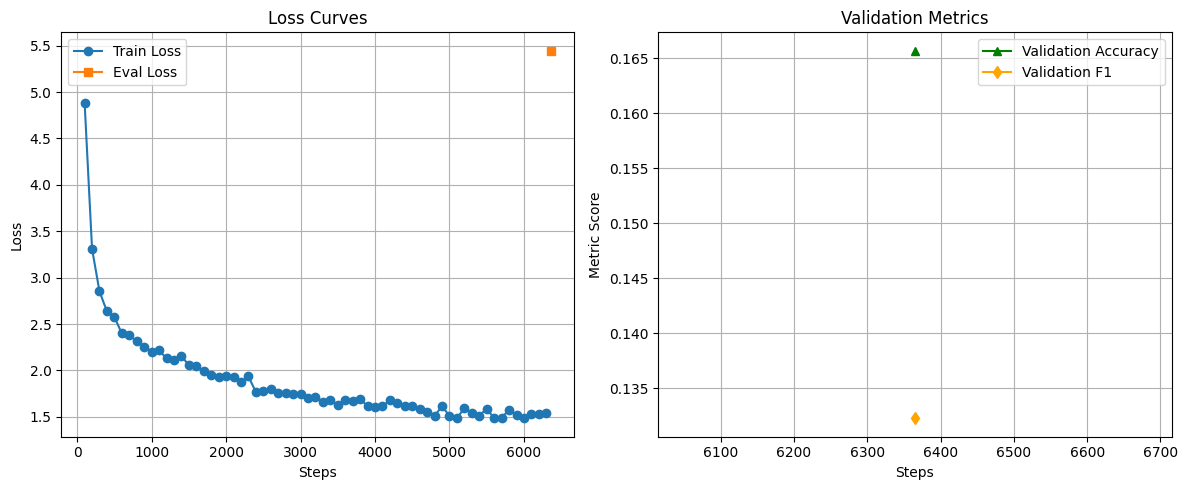

In [37]:
# 3. Plotting
plt.figure(figsize=(12, 5))

# Plot Loss if available
if not hist_train.empty or not eval_df.empty:
  plt.subplot(1, 2, 1)
  if not hist_train.empty:
    plt.plot(hist_train["step"], hist_train["loss"], label="Train Loss", marker="o")
  if not eval_df.empty:
    plt.plot(
        eval_df["step"], eval_df["eval_loss"], label="Eval Loss", marker="s"
    )
  plt.xlabel("Steps")
  plt.ylabel("Loss")
  plt.title("Loss Curves")
  plt.legend()
  plt.grid(True)

# Plot Validation Metrics (Accuracy / F1)
if not eval_df.empty:
  plt.subplot(1, 2, 2)
  if "eval_accuracy" in eval_df.columns:
    plt.plot(
        eval_df["step"],
        eval_df["eval_accuracy"],
        label="Validation Accuracy",
        marker="^",
        color="green",
    )
  if "eval_f1" in eval_df.columns:
    plt.plot(
        eval_df["step"],
        eval_df["eval_f1"],
        label="Validation F1",
        marker="d",
        color="orange",
    )
  plt.xlabel("Steps")
  plt.ylabel("Metric Score")
  plt.title("Validation Metrics")
  plt.legend()
  plt.grid(True)

plt.tight_layout()
plt.show()

In [38]:
# # Evaluate on the Test Dataset
# print("\n--- Evaluating on Test Set ---")
# test_results = trainer.evaluate(eval_dataset=tokenized_splits["validation"])
# print(test_results)

## Load the best saved model

In [39]:
# Get the checkpoint selected by Trainer.
#best_model_path =model_path# trainer.state.best_model_checkpoint
best_model_path =trainer.state.best_model_checkpoint
if best_model_path is None:
    raise ValueError(
        "Trainer has no best checkpoint recorded. "
        "Check your evaluation/checkpoint settings, or explicitly select "
        "a saved checkpoint."
    )

best_model_path = pathlib.Path(best_model_path)
print("Best checkpoint:", best_model_path)

if not (best_model_path / "adapter_config.json").is_file():
    raise FileNotFoundError(
        f"No adapter_config.json found in {best_model_path}"
    )


# Restore the trained adapter and its saved classification head.
inference_model = PeftModel.from_pretrained(
    base_model,
    best_model_path,
    is_trainable=False,
    local_files_only=True,
)

inference_model.eval()

# Use the SAME tokenizer used during training.
classifier = pipeline(
    task="text-classification",
    model=inference_model,
    tokenizer=tokenizer,
    device=device,
)

print("Best model successfully loaded from:", best_model_path)

Best checkpoint: saved_model/checkpoint-6365
Best model successfully loaded from: saved_model/checkpoint-6365


## Predictions

In [40]:
# 1. Load reserved test data
texts = competition_test_df["text"].tolist()
true_labels = competition_test_df["model"].tolist()

# 2. Generate predictions
results = classifier(texts, batch_size=16)

predicted_labels = [res["label"] for res in results]

# 3. Evaluate performance
accuracy = accuracy_score(true_labels, predicted_labels)
macro_f1 = f1_score(
    true_labels,
    predicted_labels,
    average="macro"
)
weighted_f1 = f1_score(
    true_labels,
    predicted_labels,
    average="weighted"
)

print("\n========== FINAL TEST RESULTS ==========")
print(f"Test Accuracy : {accuracy * 100:.2f}%")
print(f"Macro F1      : {macro_f1:.4f}")
print(f"Weighted F1   : {weighted_f1:.4f}")

# 4. Classification report
print("\n========== CLASSIFICATION REPORT ==========")

print(
    classification_report(
        true_labels,
        predicted_labels,
        zero_division=0,
        digits=4
    )
)

# 5. Confusion matrix
print("\n========== CONFUSION MATRIX ==========")

print(
    confusion_matrix(
        true_labels,
        predicted_labels
    )
)


========== FINAL TEST RESULTS ==========
Test Accuracy : 15.93%
Macro F1      : 0.1250
Weighted F1   : 0.1250

========== CLASSIFICATION REPORT ==========
                        precision    recall  f1-score   support

        claude-fable-5     0.0000    0.0000    0.0000        45
       claude-opus-4-6     0.1129    0.1556    0.1308        45
       claude-opus-4-8     0.1084    0.2000    0.1406        45
         claude-opus-5     0.3333    0.0222    0.0417        45
       claude-sonnet-5     0.2424    0.1778    0.2051        45
gemini-3.1-pro-preview     0.2857    0.2667    0.2759        45
      gemini-3.6-flash     0.0000    0.0000    0.0000        45
      gemini-3.7-flash     0.1935    0.1333    0.1579        45
      gemini-3.8-flash     0.1742    0.6889    0.2780        45
               glm-5.3     0.0870    0.0444    0.0588        45
         glm-5.3-flash     0.1463    0.2667    0.1890        45
               gpt-5.5     0.2593    0.1556    0.1944        45
          g

## Submission

In [41]:
TEST_PATH = (
    INPUT_DIR / "competitions/name-that-llm/test.csv"
)

test_df = pd.read_csv(TEST_PATH)
print("Original training shape:", test_df.shape)
print("Columns:", test_df.columns.tolist())
test_df.head()

Original training shape: (3, 2)
Columns: ['id', 'text']


,id,text
0,00353fb1c541,"The more efficiently we use a resource, the mo..."
1,005f5a9a6139,"The Stern-Gerlach experiment, performed in 192..."
2,0062a53d5487,"Hundreds of millions of years ago, fluctuating..."


In [42]:
results = classifier(test_df["text"].to_list(),  batch_size=16)

predicted_labels = [res['label'] for res in results]

# Submission
submission = pd.DataFrame({
    "id": test_df["id"].values,
    "model": predicted_labels
})

# Save
output_path = "/kaggle/working/submission.parquet"

submission.to_parquet(output_path, index=False)

print("\nSubmission preview:")
submission.head()


Submission preview:


,id,model
0,00353fb1c541,claude-sonnet-5
1,005f5a9a6139,gemini-3.7-flash
2,0062a53d5487,gemini-3.7-flash
